In [3]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph, START , END
import random

In [4]:
class AgentState(TypedDict):
  name:str
  number:list[int]
  counter: int

In [28]:
def greet_node(state: AgentState) -> AgentState:
  """ Simple function for greetings """
  state["name"]= f"Hey {state['name']}, How are you doing?"
  state["counter"]:0
  return state

def randomGen(state: AgentState) -> AgentState:
  """ Simple function the generates random number """
  state["number"].append(random.randint(0,10))
  state["counter"]+=1
  return state

def continueloop(state: AgentState) -> AgentState:
  """ Conditional edge to control the loop """
  if state["counter"]<5:
    print(f"Entering loop: {state['counter']}")
    return "loop"
  else:
    return "exit"


In [29]:
graph = StateGraph(AgentState)
graph.add_node("greetings", greet_node)
graph.add_node("Random", randomGen)
graph.add_edge("greetings", "Random")

graph.add_conditional_edges(
  "Random",
  continueloop,
  {
    "loop": "Random",
    "exit": END
  }
)
graph.set_entry_point("greetings")

app = graph.compile()

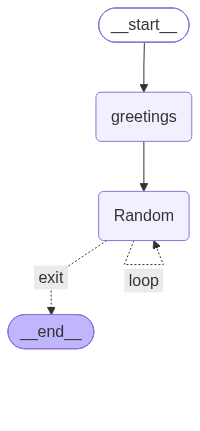

In [30]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [32]:
results = app.invoke({"name":"Bob", "number":[], "counter":0})
print(results)

Entering loop: 1
Entering loop: 2
Entering loop: 3
Entering loop: 4
{'name': 'Hey Bob, How are you doing?', 'number': [8, 5, 1, 3, 6], 'counter': 5}
